<a href="https://colab.research.google.com/github/RozieKii/localTest/blob/main/Week2_09_rag_101_retrieval_systems.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 2.4: RAG 101 - Retrieval Systems

## Key Insight
> **The pipeline: Load → Split → Embed → Retrieve → Answer**

## Learning Objectives
By the end of this notebook, you will:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [1]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!')
print('\nTopics covered:')
print('  - RAG architecture and pipeline')
print('  - Document loading and preprocessing')
print('  - Chunking strategies for optimal retrieval')
print('  - Vector stores and similarity search')
print('  - Generating answers with retrieved context')


✅ Week 2.4: RAG 101 - Retrieval Systems - Ready to start!

Topics covered:
  - RAG architecture and pipeline
  - Document loading and preprocessing
  - Chunking strategies for optimal retrieval
  - Vector stores and similarity search
  - Generating answers with retrieved context


---
## Part 1: Introduction to RAG architecture and pipeline

Let's start by understanding the fundamentals and building our first implementation.

In [2]:
class SimpleRAG:
    """A beginner-friendly RAG pipeline prototype."""

    def __init__(self, documents):
        self.documents = documents
        self.chunks = []

    def load(self):
        """Load the documents."""
        return self.documents

    def split(self, chunk_size=12):
        """Split documents into small word-based chunks."""
        self.chunks = []

        for document in self.load():
            words = document.split()

            for i in range(0, len(words), chunk_size):
                chunk = " ".join(words[i:i + chunk_size])
                if chunk:
                    self.chunks.append(chunk)

        return self.chunks

    def retrieve(self, query, top_k=2):
        """Retrieve chunks with the most query keyword matches."""
        if not self.chunks:
            self.split()

        query_words = set(re.findall(r"\b\w+\b", query.lower()))
        scored_chunks = []

        for chunk in self.chunks:
            chunk_words = set(re.findall(r"\b\w+\b", chunk.lower()))
            score = len(query_words & chunk_words)
            scored_chunks.append((score, chunk))

        scored_chunks.sort(key=lambda item: item[0], reverse=True)

        return [
            chunk for score, chunk in scored_chunks[:top_k]
            if score > 0
        ]

    def process(self, query):
        """Run retrieval and return a context-grounded draft."""
        relevant_chunks = self.retrieve(query)

        if not relevant_chunks:
            return "I couldn't find relevant information in the documents."

        context = "\n".join(relevant_chunks)
        return f"Retrieved context:\n{context}"


# Test the pipeline with PathPilot information
documents = [
    "PathPilot helps users set goals and track their personal growth.",
    "Users can explore career options and identify skills they need to develop.",
    "Regular reminders can help users stay consistent with their learning plans."
]

rag = SimpleRAG(documents)

print("Loaded documents:", len(rag.load()))
print("\nChunks:")
for chunk in rag.split(chunk_size=8):
    print("-", chunk)

print("\nQuery result:")
print(rag.process("How can I improve my career skills?"))

Loaded documents: 3

Chunks:
- PathPilot helps users set goals and track their
- personal growth.
- Users can explore career options and identify skills
- they need to develop.
- Regular reminders can help users stay consistent with
- their learning plans.

Query result:
Retrieved context:
Users can explore career options and identify skills
Regular reminders can help users stay consistent with


### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [3]:
import re

class BasicRAG:
    """A basic RAG pipeline for loading and retrieving information."""

    def __init__(self, documents):
        if not isinstance(documents, list):
            raise TypeError("Documents must be provided as a list.")

        if not all(isinstance(doc, str) for doc in documents):
            raise TypeError("Every document must be a string.")

        self.documents = [doc.strip() for doc in documents if doc.strip()]

    def process(self, query):
        """Retrieve documents that best match the query."""

        if not isinstance(query, str):
            raise TypeError("Query must be a string.")

        if not query.strip():
            raise ValueError("Query cannot be empty.")

        if not self.documents:
            return "No documents available to search."

        query_words = set(re.findall(r"\b\w+\b", query.lower()))

        if not query_words:
            return "No searchable keywords found in the query."

        scored_documents = []

        for document in self.documents:
            doc_words = set(re.findall(r"\b\w+\b", document.lower()))
            score = len(query_words & doc_words)
            scored_documents.append((score, document))

        scored_documents.sort(key=lambda item: item[0], reverse=True)

        results = [doc for score, doc in scored_documents if score > 0]

        if not results:
            return "No relevant documents found."

        return results[:2]


# Test with sample PathPilot data
documents = [
    "PathPilot helps users set and track personal goals.",
    "Users can develop career skills through learning.",
    "Regular reminders help users stay consistent."
]

rag = BasicRAG(documents)

print("Test 1 — Relevant query:")
print(rag.process("How can I develop career skills?"))

print("\nTest 2 — No matching information:")
print(rag.process("Tell me about cooking"))

print("\nTest 3 — Empty query:")
try:
    rag.process("")
except ValueError as error:
    print("Handled:", error)

print("\nTest 4 — Invalid query type:")
try:
    rag.process(123)
except TypeError as error:
    print("Handled:", error)

print("\nTest 5 — Empty document collection:")
empty_rag = BasicRAG([])
print(empty_rag.process("career skills"))

Test 1 — Relevant query:
['Users can develop career skills through learning.']

Test 2 — No matching information:
No relevant documents found.

Test 3 — Empty query:
Handled: Query cannot be empty.

Test 4 — Invalid query type:
Handled: Query must be a string.

Test 5 — Empty document collection:
No documents available to search.


---
## Part 2: Document loading and preprocessing

Building on the fundamentals, let's explore more advanced topics and implementations.

In [4]:
from typing import List, Any, Dict
import json

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """Load, validate, and preprocess text documents."""

    if not isinstance(data, list):
        raise TypeError("Input data must be a list.")

    if not all(isinstance(item, str) for item in data):
        raise TypeError("Every document must be a string.")

    remove_duplicates = kwargs.get("remove_duplicates", True)
    lowercase = kwargs.get("lowercase", False)

    if not isinstance(remove_duplicates, bool):
        raise TypeError("remove_duplicates must be True or False.")

    if not isinstance(lowercase, bool):
        raise TypeError("lowercase must be True or False.")

    cleaned_data = []

    for document in data:
        document = document.strip()

        if not document:
            continue

        if lowercase:
            document = document.lower()

        if remove_duplicates and document in cleaned_data:
            continue

        cleaned_data.append(document)

    return {
        "received": len(data),
        "processed": len(cleaned_data),
        "removed": len(data) - len(cleaned_data),
        "data": cleaned_data
    }


# Example usage
sample_data = [
    "  PathPilot helps users set goals. ",
    "Users can develop career skills.",
    "",
    "  PathPilot helps users set goals. "
]

output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

{
  "received": 4,
  "processed": 2,
  "removed": 2,
  "data": [
    "PathPilot helps users set goals.",
    "Users can develop career skills."
  ]
}


### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [5]:
from typing import List, Any, Dict

def intermediate_rag(
    data: List[Any],
    remove_duplicates: bool = True,
    lowercase: bool = False,
    min_length: int = 1
) -> Dict[str, Any]:
    """Validate, clean, and preprocess documents."""

    # 1. Validate the input collection
    if not isinstance(data, list):
        raise TypeError("data must be a list of documents.")

    if not all(isinstance(doc, str) for doc in data):
        raise TypeError("Every document must be a string.")

    # 2. Validate configuration parameters
    if not isinstance(remove_duplicates, bool):
        raise TypeError("remove_duplicates must be True or False.")

    if not isinstance(lowercase, bool):
        raise TypeError("lowercase must be True or False.")

    if isinstance(min_length, bool) or not isinstance(min_length, int):
        raise TypeError("min_length must be an integer.")

    if min_length < 1:
        raise ValueError("min_length must be at least 1.")

    # 3. Clean and filter documents
    cleaned_documents = []
    removed_blank = 0
    removed_short = 0
    removed_duplicate = 0

    for doc in data:
        doc = doc.strip()

        if not doc:
            removed_blank += 1
            continue

        if lowercase:
            doc = doc.lower()

        if len(doc) < min_length:
            removed_short += 1
            continue

        if remove_duplicates and doc in cleaned_documents:
            removed_duplicate += 1
            continue

        cleaned_documents.append(doc)

    # 4. Return processed data and a summary
    return {
        "received": len(data),
        "processed": len(cleaned_documents),
        "removed_blank": removed_blank,
        "removed_short": removed_short,
        "removed_duplicate": removed_duplicate,
        "data": cleaned_documents
    }


# TEST 1: Normal input with cleaning and duplicates
sample_data = [
    "  PathPilot helps users set goals. ",
    "Users can learn new skills.",
    "",
    "PathPilot helps users set goals.",
    "AI"
]

print("TEST 1 — Normal input")
print(intermediate_rag(sample_data, min_length=5))

# TEST 2: Lowercase and duplicate removal
print("\nTEST 2 — Lowercase")
print(intermediate_rag(
    ["Career Skills", "career skills", "  LEARNING  "],
    lowercase=True
))

# TEST 3: Keep duplicates
print("\nTEST 3 — Keep duplicates")
print(intermediate_rag(
    ["Learn AI", "Learn AI"],
    remove_duplicates=False
))

# TEST 4: Invalid input type
print("\nTEST 4 — Invalid data")
try:
    intermediate_rag("not a list")
except (TypeError, ValueError) as error:
    print("Handled:", error)

# TEST 5: Invalid document type
print("\nTEST 5 — Invalid document")
try:
    intermediate_rag(["Valid text", 123])
except (TypeError, ValueError) as error:
    print("Handled:", error)

# TEST 6: Invalid parameter
print("\nTEST 6 — Invalid min_length")
try:
    intermediate_rag(["Valid text"], min_length=0)
except (TypeError, ValueError) as error:
    print("Handled:", error)

TEST 1 — Normal input
{'received': 5, 'processed': 2, 'removed_blank': 1, 'removed_short': 1, 'removed_duplicate': 1, 'data': ['PathPilot helps users set goals.', 'Users can learn new skills.']}

TEST 2 — Lowercase
{'received': 3, 'processed': 2, 'removed_blank': 0, 'removed_short': 0, 'removed_duplicate': 1, 'data': ['career skills', 'learning']}

TEST 3 — Keep duplicates
{'received': 2, 'processed': 2, 'removed_blank': 0, 'removed_short': 0, 'removed_duplicate': 0, 'data': ['Learn AI', 'Learn AI']}

TEST 4 — Invalid data
Handled: data must be a list of documents.

TEST 5 — Invalid document
Handled: Every document must be a string.

TEST 6 — Invalid min_length
Handled: min_length must be at least 1.


---
## Part 3: Chunking strategies for optimal retrieval

Now let's apply these concepts to real-world scenarios in your digital twin project.

Number of chunks: 4
Chunk 1: PathPilot helps users set personal goals and track progress. Learners
Chunk 2: progress. Learners can explore career options and identify skills to
Chunk 3: skills to develop. Regular reminders help users stay consistent with
Chunk 4: consistent with their learning plans.


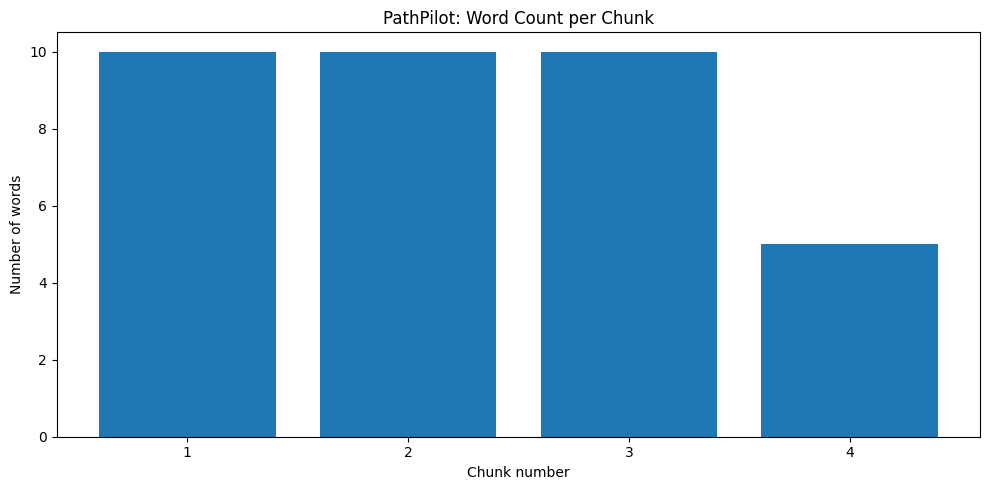

In [6]:
import matplotlib.pyplot as plt
from typing import List, Any

def chunk_text(text: str, chunk_size: int = 10, overlap: int = 2) -> List[str]:
    """Split text into chunks with optional word overlap."""

    if not isinstance(text, str):
        raise TypeError("text must be a string.")

    if not isinstance(chunk_size, int) or isinstance(chunk_size, bool) or chunk_size < 1:
        raise ValueError("chunk_size must be a positive integer.")

    if not isinstance(overlap, int) or isinstance(overlap, bool):
        raise TypeError("overlap must be an integer.")

    if overlap < 0 or overlap >= chunk_size:
        raise ValueError("overlap must be >= 0 and smaller than chunk_size.")

    words = text.split()
    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(words), step):
        chunk = words[start:start + chunk_size]
        if chunk:
            chunks.append(" ".join(chunk))

        if start + chunk_size >= len(words):
            break

    return chunks


def visualize_results(data: List[Any]):
    """Plot the word count of each chunk."""

    if not isinstance(data, list) or not all(isinstance(item, str) for item in data):
        raise TypeError("data must be a list of text chunks.")

    if not data:
        print("No chunks to visualize.")
        return

    word_counts = [len(chunk.split()) for chunk in data]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(range(1, len(data) + 1), word_counts)
    ax.set_title("PathPilot: Word Count per Chunk")
    ax.set_xlabel("Chunk number")
    ax.set_ylabel("Number of words")
    ax.set_xticks(range(1, len(data) + 1))
    plt.tight_layout()
    plt.show()


# Example PathPilot document
document = (
    "PathPilot helps users set personal goals and track progress. "
    "Learners can explore career options and identify skills to develop. "
    "Regular reminders help users stay consistent with their learning plans."
)

chunks = chunk_text(document, chunk_size=10, overlap=2)

print("Number of chunks:", len(chunks))
for i, chunk in enumerate(chunks, start=1):
    print(f"Chunk {i}: {chunk}")

visualize_results(chunks)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation


--- DOCUMENT PROCESSING ---
{'documents_received': 6, 'documents_loaded': 4, 'chunks_created': 0, 'queries_processed': 0}

--- CHUNKS ---
{'source_id': 0, 'chunk_id': 0, 'text': 'PathPilot helps users set goals and track progress.', 'word_count': 8}
{'source_id': 1, 'chunk_id': 1, 'text': 'Learners can explore career options and develop skills.', 'word_count': 8}
{'source_id': 2, 'chunk_id': 2, 'text': 'Regular reminders help users stay consistent with learning.', 'word_count': 8}
{'source_id': 3, 'chunk_id': 3, 'text': 'Saving regularly can help build financial habits.', 'word_count': 7}

--- RETRIEVAL TEST ---
Based on the retrieved information:
Learners can explore career options and develop skills.
Saving regularly can help build financial habits.
Source IDs: [1, 3]

--- NO-MATCH TEST ---
I couldn't find relevant information in the available documents.

--- ERROR HANDLING TESTS ---
Empty query handled: query cannot be empty.
Invalid top_k handled: top_k must be at least 1.
Invalid

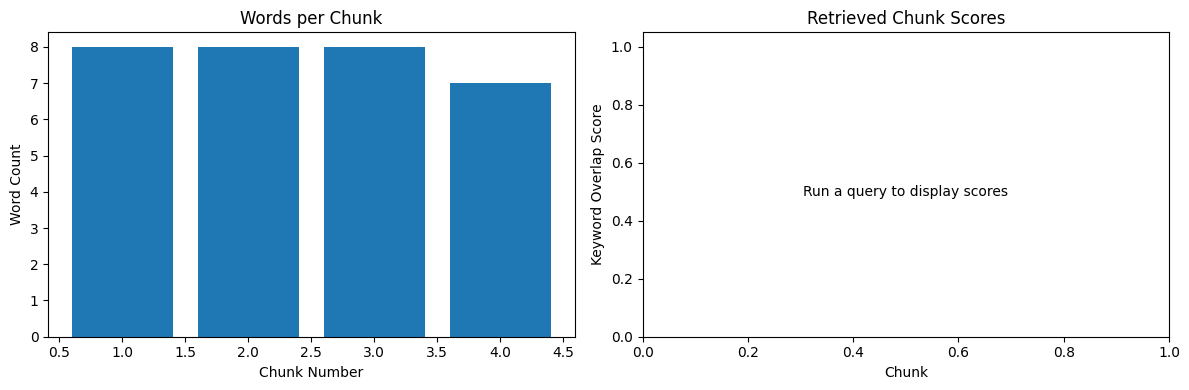


--- FINAL STATISTICS ---
{'documents_received': 6, 'documents_loaded': 4, 'chunks_created': 4, 'queries_processed': 2}

All demonstration steps completed.


In [7]:

import re
import logging
import matplotlib.pyplot as plt
from typing import List, Dict, Any


# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format="%(levelname)s: %(message)s"
)
logger = logging.getLogger("ProductionSystem")


class ProductionSystem:
    """
    Integrated RAG prototype for the PathPilot digital twin.

    Features:
    - Document validation and preprocessing
    - Duplicate removal
    - Overlapping text chunking
    - Keyword-based retrieval and ranking
    - Source tracking and fallback responses
    - Logging, error handling, and visualization

    Note: This is an educational prototype. Production deployment
    would require semantic embeddings, a persistent vector database,
    an LLM, security controls, and further testing.
    """

    def __init__(
        self,
        documents: List[str] = None,
        chunk_size: int = 30,
        overlap: int = 5
    ):
        """Initialize and validate the RAG system."""

        if documents is None:
            documents = []

        if not isinstance(documents, list):
            raise TypeError("documents must be a list of strings.")

        if not all(isinstance(doc, str) for doc in documents):
            raise TypeError("Every document must be a string.")

        if isinstance(chunk_size, bool) or not isinstance(chunk_size, int):
            raise TypeError("chunk_size must be an integer.")

        if chunk_size < 1:
            raise ValueError("chunk_size must be at least 1.")

        if isinstance(overlap, bool) or not isinstance(overlap, int):
            raise TypeError("overlap must be an integer.")

        if overlap < 0 or overlap >= chunk_size:
            raise ValueError(
                "overlap must be non-negative and smaller than chunk_size."
            )

        self.chunk_size = chunk_size
        self.overlap = overlap
        self.documents = []
        self.chunks = []
        self.last_results = []

        self.stats = {
            "documents_received": len(documents),
            "documents_loaded": 0,
            "chunks_created": 0,
            "queries_processed": 0
        }

        self.load_documents(documents)

    @staticmethod
    def tokenize(text: str) -> List[str]:
        """Convert text to lowercase word tokens."""
        return re.findall(r"\b\w+\b", text.lower())

    def load_documents(self, documents: List[str]) -> None:
        """Clean documents and remove blanks and duplicates."""

        seen = set()
        self.documents = []

        for document in documents:
            cleaned = document.strip()

            if not cleaned:
                logger.warning("Skipping blank document.")
                continue

            key = cleaned.casefold()

            if key in seen:
                logger.info("Skipping duplicate document.")
                continue

            seen.add(key)
            self.documents.append(cleaned)

        self.stats["documents_loaded"] = len(self.documents)

        logger.info(
            "Loaded %d unique documents.",
            len(self.documents)
        )

    def chunk_documents(self) -> List[Dict[str, Any]]:
        """Split documents into overlapping chunks."""

        chunks = []
        step = self.chunk_size - self.overlap

        for source_id, document in enumerate(self.documents):
            words = document.split()

            for start in range(0, len(words), step):
                chunk_words = words[start:start + self.chunk_size]

                if not chunk_words:
                    break

                chunks.append({
                    "source_id": source_id,
                    "chunk_id": len(chunks),
                    "text": " ".join(chunk_words),
                    "word_count": len(chunk_words)
                })

                if start + self.chunk_size >= len(words):
                    break

        self.chunks = chunks
        self.stats["chunks_created"] = len(chunks)

        logger.info("Created %d chunks.", len(chunks))
        return chunks

    def retrieve(
        self,
        query: str,
        top_k: int = 3
    ) -> List[Dict[str, Any]]:
        """Retrieve and rank chunks using keyword overlap."""

        if not isinstance(query, str):
            raise TypeError("query must be a string.")

        if not query.strip():
            raise ValueError("query cannot be empty.")

        if isinstance(top_k, bool) or not isinstance(top_k, int):
            raise TypeError("top_k must be an integer.")

        if top_k < 1:
            raise ValueError("top_k must be at least 1.")

        query_tokens = set(self.tokenize(query))

        if not query_tokens:
            raise ValueError("query must contain searchable words.")

        if not self.chunks:
            self.chunk_documents()

        self.stats["queries_processed"] += 1
        ranked = []

        for chunk in self.chunks:
            chunk_tokens = set(self.tokenize(chunk["text"]))
            matches = query_tokens.intersection(chunk_tokens)

            score = len(matches) / len(query_tokens)

            if score > 0:
                ranked.append({
                    **chunk,
                    "score": score,
                    "matched_terms": sorted(matches)
                })

        ranked.sort(
            key=lambda item: item["score"],
            reverse=True
        )

        self.last_results = ranked[:top_k]

        logger.info(
            "Retrieved %d relevant chunks.",
            len(self.last_results)
        )

        return self.last_results

    def process(self, input_data: str) -> Dict[str, Any]:
        """Process a user query and return a grounded response draft."""

        results = self.retrieve(input_data)

        if not results:
            logger.warning("No relevant information found.")

            return {
                "query": input_data,
                "answer": (
                    "I couldn't find relevant information "
                    "in the available documents."
                ),
                "sources": [],
                "results": []
            }

        context = "\n".join(
            item["text"] for item in results
        )

        return {
            "query": input_data,
            "answer": (
                "Based on the retrieved information:\n" + context
            ),
            "sources": sorted({
                item["source_id"] for item in results
            }),
            "results": results
        }

    def visualize(self) -> None:
        """Visualize chunk sizes and the latest retrieval scores."""

        if not self.chunks:
            self.chunk_documents()

        if not self.chunks:
            print("No chunks available to visualize.")
            return

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        word_counts = [
            chunk["word_count"] for chunk in self.chunks
        ]

        axes[0].bar(
            range(1, len(word_counts) + 1),
            word_counts
        )
        axes[0].set_title("Words per Chunk")
        axes[0].set_xlabel("Chunk Number")
        axes[0].set_ylabel("Word Count")

        if self.last_results:
            labels = [
                f"Chunk {item['chunk_id']}"
                for item in self.last_results
            ]
            scores = [
                item["score"] for item in self.last_results
            ]

            axes[1].bar(labels, scores)
            axes[1].tick_params(axis="x", rotation=30)
        else:
            axes[1].text(
                0.5, 0.5,
                "Run a query to display scores",
                ha="center",
                va="center"
            )

        axes[1].set_title("Retrieved Chunk Scores")
        axes[1].set_xlabel("Chunk")
        axes[1].set_ylabel("Keyword Overlap Score")
        axes[1].set_ylim(0, 1.05)

        plt.tight_layout()
        plt.show()


# --------------------------------------------------
# TEST THE PRODUCTION SYSTEM
# --------------------------------------------------

sample_documents = [
    "PathPilot helps users set goals and track progress.",
    "Learners can explore career options and develop skills.",
    "Regular reminders help users stay consistent with learning.",
    "Saving regularly can help build financial habits.",
    "Learners can explore career options and develop skills.",
    "   "
]

system = ProductionSystem(
    documents=sample_documents,
    chunk_size=12,
    overlap=3
)

print("\n--- DOCUMENT PROCESSING ---")
print(system.stats)

print("\n--- CHUNKS ---")
for chunk in system.chunk_documents():
    print(chunk)

print("\n--- RETRIEVAL TEST ---")
result = system.process("How can I develop career skills?")
print(result["answer"])
print("Source IDs:", result["sources"])

print("\n--- NO-MATCH TEST ---")
print(system.process("volcano astronomy")["answer"])

print("\n--- ERROR HANDLING TESTS ---")

try:
    system.process("")
except ValueError as error:
    print("Empty query handled:", error)

try:
    system.retrieve("career skills", top_k=0)
except ValueError as error:
    print("Invalid top_k handled:", error)

try:
    ProductionSystem(
        documents=["Example"],
        chunk_size=5,
        overlap=5
    )
except ValueError as error:
    print("Invalid overlap handled:", error)

try:
    ProductionSystem(documents=["Valid", 123])
except TypeError as error:
    print("Invalid document handled:", error)

print("\n--- VISUALIZATION ---")
system.visualize()

print("\n--- FINAL STATISTICS ---")
print(system.stats)

print("\nAll demonstration steps completed.")


---
## Summary & Key Takeaways

### What We Learned:
- RAG architecture and pipeline
- Document loading and preprocessing
- Chunking strategies for optimal retrieval
- Vector stores and similarity search
- Generating answers with retrieved context

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete RAG architecture and pipeline System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code